# Import the libraries

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


# Import the dataset

In [ ]:
df = pd.read_csv('HeartDiseases.csv')

print("Dataset Info: ",df.shape)
print()
print(df.head())


Dataset Info:  (270, 5)

   age  sex   BP  cholestrol  heart disease
0   70    1  130         322              1
1   67    0  115         564              0
2   57    1  124         261              1
3   64    1  128         263              0
4   74    0  120         269              0


In [ ]:
df.groupby(['heart disease']).size()

,0
heart disease,
0,150
1,120


Text(0.5, 1.0, 'Value counts of heart disease patients')

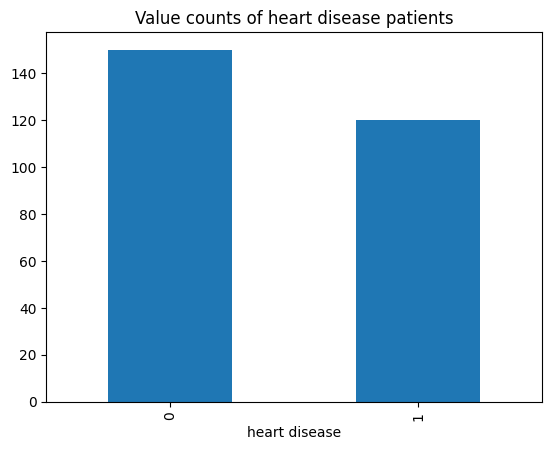

In [ ]:
df.groupby(['heart disease']).size().plot(kind = "bar")
plt.title('Value counts of heart disease patients')

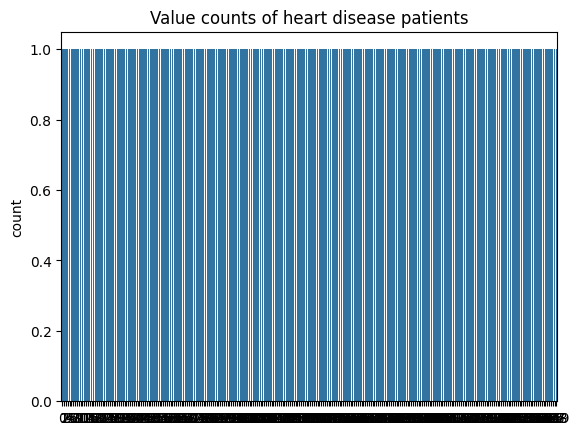

In [ ]:
sns.countplot(df['heart disease'])
plt.title('Value counts of heart disease patients')
plt.show()

# Putting Feature Variable to X and Target variable to y.

In [ ]:
# Putting feature variable to X
X = df.drop('heart disease',axis=1)
# Putting response variable to y
y = df['heart disease']

# Train-Test-Split is performed

In [ ]:
# now lets split the data into train and test
from sklearn.model_selection import train_test_split

# Splitting the data into train and test
X_train, X_test, y_train, y_test = train_test_split(X, y, train_size=0.7, random_state=42)
X_train.shape, X_test.shape

((189, 4), (81, 4))

# Import RandomForestClassifier and fit the data.

In [ ]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(random_state=42, n_jobs=-1, max_depth=5,
                                       n_estimators=100, oob_score=True)


rf_model.fit(X_train, y_train)
# checking the oob score
rf_model.oob_score_

0.656084656084656

In [ ]:
# Predict on the test set results

y_predict = rf_model.predict(X_test)


In [ ]:
# Check accuracy score

from sklearn.metrics import accuracy_score

print('Model accuracy score with 100 decision-trees : {0:0.4f}'. format(accuracy_score(y_test, y_predict)))

Model accuracy score with 100 decision-trees : 0.6543


In [ ]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_predict)

print('Confusion matrix\n\n', cm)

Confusion matrix

 [[36 13]
 [15 17]]


In [ ]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_predict))

              precision    recall  f1-score   support

           0       0.71      0.73      0.72        49
           1       0.57      0.53      0.55        32

    accuracy                           0.65        81
   macro avg       0.64      0.63      0.63        81
weighted avg       0.65      0.65      0.65        81



## Train and Evaluate Gradient Boosting Classifier

### Subtask:
Initialize, train, and evaluate a Gradient Boosting Classifier model using `X_train` and `y_train`. Then, predict on `X_test` and calculate its accuracy, confusion matrix, and classification report. Store the accuracy for comparison.

**Reasoning**:
The subtask is to train and evaluate a Gradient Boosting Classifier model. This code block will initialize, train, predict, and evaluate the model, then store its accuracy in the `model_accuracies` dictionary for later comparison.



In [ ]:
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# Initialize a GradientBoostingClassifier model
gbc_model = GradientBoostingClassifier(random_state=42)

# Train the model
gbc_model.fit(X_train, y_train)

# Make predictions on the test set
y_pred_gbc = gbc_model.predict(X_test)

# Calculate accuracy score
accuracy_gbc = accuracy_score(y_test, y_pred_gbc)
print(f'Gradient Boosting Classifier Model accuracy score: {accuracy_gbc:.4f}')

# Calculate confusion matrix
cm_gbc = confusion_matrix(y_test, y_pred_gbc)
print('\nConfusion matrix for Gradient Boosting Classifier:\n', cm_gbc)

# Generate classification report
report_gbc = classification_report(y_test, y_pred_gbc)
print('\nClassification Report for Gradient Boosting Classifier:\n', report_gbc)

# Store the accuracy score for comparison
model_accuracies['Gradient Boosting Classifier'] = accuracy_gbc

print(f'\nModel Accuracies so far: {model_accuracies}')

## Train and Evaluate Gaussian Naive Bayes

### Subtask:
Initialize, train, and evaluate a Gaussian Naive Bayes model using `X_train` and `y_train`. Then, predict on `X_test` and calculate its accuracy, confusion matrix, and classification report. Store the accuracy for comparison.

**Reasoning**:
The subtask is to train and evaluate a Gaussian Naive Bayes model. This code block will initialize, train, predict, and evaluate the model, then store its accuracy in the `model_accuracies` dictionary for later comparison.



In [12]:
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# Initialize a Gaussian Naive Bayes model
gnb_model = GaussianNB()

# Train the model
gnb_model.fit(X_train, y_train)

# Make predictions on the test set
y_pred_gnb = gnb_model.predict(X_test)

# Calculate accuracy score
accuracy_gnb = accuracy_score(y_test, y_pred_gnb)
print(f'Gaussian Naive Bayes Model accuracy score: {accuracy_gnb:.4f}')

# Calculate confusion matrix
cm_gnb = confusion_matrix(y_test, y_pred_gnb)
print('\nConfusion matrix for Gaussian Naive Bayes:\n', cm_gnb)

# Generate classification report
report_gnb = classification_report(y_test, y_pred_gnb)
print('\nClassification Report for Gaussian Naive Bayes:\n', report_gnb)

# Store the accuracy score for comparison
model_accuracies['Gaussian Naive Bayes'] = accuracy_gnb

print(f'\nModel Accuracies so far: {model_accuracies}')

Gaussian Naive Bayes Model accuracy score: 0.6667

Confusion matrix for Gaussian Naive Bayes:
 [[35 14]
 [13 19]]

Classification Report for Gaussian Naive Bayes:
               precision    recall  f1-score   support

           0       0.73      0.71      0.72        49
           1       0.58      0.59      0.58        32

    accuracy                           0.67        81
   macro avg       0.65      0.65      0.65        81
weighted avg       0.67      0.67      0.67        81


Model Accuracies so far: {'Logistic Regression': 0.7037037037037037, 'Decision Tree': 0.6296296296296297, 'Support Vector Machine': 0.6790123456790124, 'Gaussian Naive Bayes': 0.6666666666666666, 'Gradient Boosting Classifier': 0.5555555555555556, 'Random Forest Classifier': 0.654320987654321}


# Task
Train and evaluate Logistic Regression, Decision Tree, Support Vector Machine (SVM), Gaussian Naive Bayes, and Gradient Boosting Classifier models on the `HeartDiseases.csv` dataset. Compare their performance, along with the previously trained RandomForestClassifier, using accuracy scores and visualize the results. Finally, summarize the performance of all models and identify the best-performing one.

## Import Machine Learning Models

### Subtask:
Import the necessary classes for Logistic Regression, Decision Tree Classifier, Support Vector Classifier, Gaussian Naive Bayes, and Gradient Boosting Classifier from `sklearn`.


**Reasoning**:
The user wants to import various machine learning models from `sklearn` as per the instructions. This code block will import all the specified classes.



In [1]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB
from sklearn.ensemble import GradientBoostingClassifier

print("Imported necessary machine learning models successfully.")

Imported necessary machine learning models successfully.


## Train and Evaluate Logistic Regression

### Subtask:
Initialize, train, and evaluate a Logistic Regression model using `X_train` and `y_train`. Then, predict on `X_test` and calculate its accuracy, confusion matrix, and classification report. Store the accuracy for comparison.


**Reasoning**:
The subtask requires initializing, training, and evaluating a Logistic Regression model, then storing its accuracy for comparison. This code block will perform all these actions as per the instructions, including initializing the `model_accuracies` dictionary if it doesn't exist.



In [2]:
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# Initialize a LogisticRegression model
logreg_model = LogisticRegression(random_state=42, solver='liblinear', max_iter=1000)

# Train the model
logreg_model.fit(X_train, y_train)

# Make predictions on the test set
y_pred_lr = logreg_model.predict(X_test)

# Calculate accuracy score
accuracy_lr = accuracy_score(y_test, y_pred_lr)
print(f'Logistic Regression Model accuracy score: {accuracy_lr:.4f}')

# Calculate confusion matrix
cm_lr = confusion_matrix(y_test, y_pred_lr)
print('\nConfusion matrix for Logistic Regression:\n', cm_lr)

# Generate classification report
report_lr = classification_report(y_test, y_pred_lr)
print('\nClassification Report for Logistic Regression:\n', report_lr)

# Store the accuracy score for comparison
if 'model_accuracies' not in locals():
    model_accuracies = {}
model_accuracies['Logistic Regression'] = accuracy_lr

print(f'\nModel Accuracies so far: {model_accuracies}')

NameError: name 'X_train' is not defined

**Reasoning**:
The previous execution failed because 'X_train' and 'y_train' were not defined. This is likely due to the train-test split cell not being executed. To fix this, I will include the code that defines X and y from the dataframe, and then perform the train-test split to ensure that X_train, X_test, y_train, and y_test are available for the Logistic Regression model.



In [3]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# Ensure df, X, and y are defined before train-test split
df = pd.read_csv('HeartDiseases.csv') # Re-load df if not in kernel state
X = df.drop('heart disease',axis=1)
y = df['heart disease']

# Splitting the data into train and test (re-executing this step)
X_train, X_test, y_train, y_test = train_test_split(X, y, train_size=0.7, random_state=42)

# Initialize a LogisticRegression model
logreg_model = LogisticRegression(random_state=42, solver='liblinear', max_iter=1000)

# Train the model
logreg_model.fit(X_train, y_train)

# Make predictions on the test set
y_pred_lr = logreg_model.predict(X_test)

# Calculate accuracy score
accuracy_lr = accuracy_score(y_test, y_pred_lr)
print(f'Logistic Regression Model accuracy score: {accuracy_lr:.4f}')

# Calculate confusion matrix
cm_lr = confusion_matrix(y_test, y_pred_lr)
print('\nConfusion matrix for Logistic Regression:\n', cm_lr)

# Generate classification report
report_lr = classification_report(y_test, y_pred_lr)
print('\nClassification Report for Logistic Regression:\n', report_lr)

# Store the accuracy score for comparison
if 'model_accuracies' not in locals():
    model_accuracies = {}
model_accuracies['Logistic Regression'] = accuracy_lr

print(f'\nModel Accuracies so far: {model_accuracies}')

Logistic Regression Model accuracy score: 0.7037

Confusion matrix for Logistic Regression:
 [[35 14]
 [10 22]]

Classification Report for Logistic Regression:
               precision    recall  f1-score   support

           0       0.78      0.71      0.74        49
           1       0.61      0.69      0.65        32

    accuracy                           0.70        81
   macro avg       0.69      0.70      0.70        81
weighted avg       0.71      0.70      0.71        81


Model Accuracies so far: {'Logistic Regression': 0.7037037037037037}


## Train and Evaluate Decision Tree Classifier

### Subtask:
Initialize, train, and evaluate a Decision Tree Classifier model using `X_train` and `y_train`. Then, predict on `X_test` and calculate its accuracy, confusion matrix, and classification report. Store the accuracy for comparison.

**Reasoning**:
The subtask is to train and evaluate a Decision Tree Classifier. This code block will initialize, train, predict, and evaluate the model, then store its accuracy in the `model_accuracies` dictionary for later comparison.



In [4]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# Initialize a DecisionTreeClassifier model
dtc_model = DecisionTreeClassifier(random_state=42)

# Train the model
dtc_model.fit(X_train, y_train)

# Make predictions on the test set
y_pred_dtc = dtc_model.predict(X_test)

# Calculate accuracy score
accuracy_dtc = accuracy_score(y_test, y_pred_dtc)
print(f'Decision Tree Classifier Model accuracy score: {accuracy_dtc:.4f}')

# Calculate confusion matrix
cm_dtc = confusion_matrix(y_test, y_pred_dtc)
print('\nConfusion matrix for Decision Tree Classifier:\n', cm_dtc)

# Generate classification report
report_dtc = classification_report(y_test, y_pred_dtc)
print('\nClassification Report for Decision Tree Classifier:\n', report_dtc)

# Store the accuracy score for comparison
model_accuracies['Decision Tree'] = accuracy_dtc

print(f'\nModel Accuracies so far: {model_accuracies}')

Decision Tree Classifier Model accuracy score: 0.6296

Confusion matrix for Decision Tree Classifier:
 [[31 18]
 [12 20]]

Classification Report for Decision Tree Classifier:
               precision    recall  f1-score   support

           0       0.72      0.63      0.67        49
           1       0.53      0.62      0.57        32

    accuracy                           0.63        81
   macro avg       0.62      0.63      0.62        81
weighted avg       0.64      0.63      0.63        81


Model Accuracies so far: {'Logistic Regression': 0.7037037037037037, 'Decision Tree': 0.6296296296296297}


## Train and Evaluate Support Vector Machine (SVM)

### Subtask:
Initialize, train, and evaluate a Support Vector Machine (SVM) model using `X_train` and `y_train`. Then, predict on `X_test` and calculate its accuracy, confusion matrix, and classification report. Store the accuracy for comparison.

**Reasoning**:
The subtask is to train and evaluate a Support Vector Machine (SVM) model. This code block will initialize, train, predict, and evaluate the model, then store its accuracy in the `model_accuracies` dictionary for later comparison.



In [5]:
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# Initialize an SVC model
svm_model = SVC(random_state=42)

# Train the model
svm_model.fit(X_train, y_train)

# Make predictions on the test set
y_pred_svm = svm_model.predict(X_test)

# Calculate accuracy score
accuracy_svm = accuracy_score(y_test, y_pred_svm)
print(f'Support Vector Machine Model accuracy score: {accuracy_svm:.4f}')

# Calculate confusion matrix
cm_svm = confusion_matrix(y_test, y_pred_svm)
print('\nConfusion matrix for Support Vector Machine:\n', cm_svm)

# Generate classification report
report_svm = classification_report(y_test, y_pred_svm)
print('\nClassification Report for Support Vector Machine:\n', report_svm)

# Store the accuracy score for comparison
model_accuracies['Support Vector Machine'] = accuracy_svm

print(f'\nModel Accuracies so far: {model_accuracies}')

Support Vector Machine Model accuracy score: 0.6790

Confusion matrix for Support Vector Machine:
 [[42  7]
 [19 13]]

Classification Report for Support Vector Machine:
               precision    recall  f1-score   support

           0       0.69      0.86      0.76        49
           1       0.65      0.41      0.50        32

    accuracy                           0.68        81
   macro avg       0.67      0.63      0.63        81
weighted avg       0.67      0.68      0.66        81


Model Accuracies so far: {'Logistic Regression': 0.7037037037037037, 'Decision Tree': 0.6296296296296297, 'Support Vector Machine': 0.6790123456790124}


## Compare Model Performance using Multiple Metrics

### Subtask:
Calculate and display accuracy, precision, recall, and F1-score for all trained models. Summarize these metrics in a table for comprehensive comparison.

**Reasoning**:
The user wants to compare models based on additional metrics (precision, recall, F1-score) beyond accuracy. This code block will calculate these metrics for each trained model using their respective predictions (`y_pred_lr`, `y_pred_dtc`, `y_pred_svm`, `y_pred_gnb`, `y_pred_gbc`, `y_predict` for Random Forest). The results will be stored in a dictionary and then converted to a Pandas DataFrame for clear, tabular presentation, allowing for easy comparison of all models across multiple performance indicators.

In [13]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
import pandas as pd

# Dictionary to store all metrics for each model
all_model_metrics = {}

# Define models and their predictions
models = {
    'Logistic Regression': y_pred_lr,
    'Decision Tree': y_pred_dtc,
    'Support Vector Machine': y_pred_svm,
    'Gaussian Naive Bayes': y_pred_gnb,
    'Gradient Boosting Classifier': y_pred_gbc,
    'Random Forest Classifier': y_predict
}

for model_name, y_predicted in models.items():
    accuracy = accuracy_score(y_test, y_predicted)
    precision = precision_score(y_test, y_predicted)
    recall = recall_score(y_test, y_predicted)
    f1 = f1_score(y_test, y_predicted)

    all_model_metrics[model_name] = {
        'Accuracy': accuracy,
        'Precision': precision,
        'Recall': recall,
        'F1-Score': f1
    }

# Convert the dictionary to a DataFrame for a clear table
metrics_df = pd.DataFrame(all_model_metrics).T # .T transposes the DataFrame

print('\nComparison of Model Performance Metrics:\n')
display(metrics_df.round(4))

# You can also sort by accuracy or any other metric
print('\nComparison of Model Performance Metrics (Sorted by Accuracy):\n')
display(metrics_df.sort_values(by='Accuracy', ascending=False).round(4))



Comparison of Model Performance Metrics:



,Accuracy,Precision,Recall,F1-Score
Logistic Regression,0.7037,0.6111,0.6875,0.6471
Decision Tree,0.6296,0.5263,0.6250,0.5714
Support Vector Machine,0.6790,0.6500,0.4062,0.5000
Gaussian Naive Bayes,0.6667,0.5758,0.5938,0.5846
Gradient Boosting Classifier,0.5556,0.4375,0.4375,0.4375
Random Forest Classifier,0.6543,0.5667,0.5312,0.5484



Comparison of Model Performance Metrics (Sorted by Accuracy):



,Accuracy,Precision,Recall,F1-Score
Logistic Regression,0.7037,0.6111,0.6875,0.6471
Support Vector Machine,0.6790,0.6500,0.4062,0.5000
Gaussian Naive Bayes,0.6667,0.5758,0.5938,0.5846
Random Forest Classifier,0.6543,0.5667,0.5312,0.5484
Decision Tree,0.6296,0.5263,0.6250,0.5714
Gradient Boosting Classifier,0.5556,0.4375,0.4375,0.4375


## Train and Evaluate Gaussian Naive Bayes

### Subtask:
Initialize, train, and evaluate a Gaussian Naive Bayes model using `X_train` and `y_train`. Then, predict on `X_test` and calculate its accuracy, confusion matrix, and classification report. Store the accuracy for comparison.

**Reasoning**:
The subtask is to train and evaluate a Gaussian Naive Bayes model. This code block will initialize, train, predict, and evaluate the model, then store its accuracy in the `model_accuracies` dictionary for later comparison.



In [6]:
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# Initialize a Gaussian Naive Bayes model
gnb_model = GaussianNB()

# Train the model
gnb_model.fit(X_train, y_train)

# Make predictions on the test set
y_pred_gnb = gnb_model.predict(X_test)

# Calculate accuracy score
accuracy_gnb = accuracy_score(y_test, y_pred_gnb)
print(f'Gaussian Naive Bayes Model accuracy score: {accuracy_gnb:.4f}')

# Calculate confusion matrix
cm_gnb = confusion_matrix(y_test, y_pred_gnb)
print('\nConfusion matrix for Gaussian Naive Bayes:\n', cm_gnb)

# Generate classification report
report_gnb = classification_report(y_test, y_pred_gnb)
print('\nClassification Report for Gaussian Naive Bayes:\n', report_gnb)

# Store the accuracy score for comparison
model_accuracies['Gaussian Naive Bayes'] = accuracy_gnb

print(f'\nModel Accuracies so far: {model_accuracies}')

Gaussian Naive Bayes Model accuracy score: 0.6667

Confusion matrix for Gaussian Naive Bayes:
 [[35 14]
 [13 19]]

Classification Report for Gaussian Naive Bayes:
               precision    recall  f1-score   support

           0       0.73      0.71      0.72        49
           1       0.58      0.59      0.58        32

    accuracy                           0.67        81
   macro avg       0.65      0.65      0.65        81
weighted avg       0.67      0.67      0.67        81


Model Accuracies so far: {'Logistic Regression': 0.7037037037037037, 'Decision Tree': 0.6296296296296297, 'Support Vector Machine': 0.6790123456790124, 'Gaussian Naive Bayes': 0.6666666666666666}


## Train and Evaluate Gradient Boosting Classifier

### Subtask:
Initialize, train, and evaluate a Gradient Boosting Classifier model using `X_train` and `y_train`. Then, predict on `X_test` and calculate its accuracy, confusion matrix, and classification report. Store the accuracy for comparison.

**Reasoning**:
The subtask is to train and evaluate a Gradient Boosting Classifier model. This code block will initialize, train, predict, and evaluate the model, then store its accuracy in the `model_accuracies` dictionary for later comparison.



In [7]:
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# Initialize a GradientBoostingClassifier model
gbc_model = GradientBoostingClassifier(random_state=42)

# Train the model
gbc_model.fit(X_train, y_train)

# Make predictions on the test set
y_pred_gbc = gbc_model.predict(X_test)

# Calculate accuracy score
accuracy_gbc = accuracy_score(y_test, y_pred_gbc)
print(f'Gradient Boosting Classifier Model accuracy score: {accuracy_gbc:.4f}')

# Calculate confusion matrix
cm_gbc = confusion_matrix(y_test, y_pred_gbc)
print('\nConfusion matrix for Gradient Boosting Classifier:\n', cm_gbc)

# Generate classification report
report_gbc = classification_report(y_test, y_pred_gbc)
print('\nClassification Report for Gradient Boosting Classifier:\n', report_gbc)

# Store the accuracy score for comparison
model_accuracies['Gradient Boosting Classifier'] = accuracy_gbc

print(f'\nModel Accuracies so far: {model_accuracies}')

Gradient Boosting Classifier Model accuracy score: 0.5556

Confusion matrix for Gradient Boosting Classifier:
 [[31 18]
 [18 14]]

Classification Report for Gradient Boosting Classifier:
               precision    recall  f1-score   support

           0       0.63      0.63      0.63        49
           1       0.44      0.44      0.44        32

    accuracy                           0.56        81
   macro avg       0.54      0.54      0.54        81
weighted avg       0.56      0.56      0.56        81


Model Accuracies so far: {'Logistic Regression': 0.7037037037037037, 'Decision Tree': 0.6296296296296297, 'Support Vector Machine': 0.6790123456790124, 'Gaussian Naive Bayes': 0.6666666666666666, 'Gradient Boosting Classifier': 0.5555555555555556}


**Reasoning**:
The RandomForestClassifier was trained earlier in the notebook, but its accuracy was not stored in the `model_accuracies` dictionary. To enable comparison with the newly trained models, I need to calculate its accuracy on the test set and add it to the `model_accuracies` dictionary.



In [8]:
from sklearn.metrics import accuracy_score

# The RandomForestClassifier model (rf_model) was trained in cell ae34500c
# and predictions (y_predict) were made in cell 8ca0a770

# Calculate accuracy score for RandomForestClassifier
accuracy_rf = accuracy_score(y_test, y_predict)
print(f'Random Forest Classifier Model accuracy score: {accuracy_rf:.4f}')

# Store the accuracy score for comparison
model_accuracies['Random Forest Classifier'] = accuracy_rf

print(f'\nModel Accuracies after adding Random Forest: {model_accuracies}')

NameError: name 'y_predict' is not defined

**Reasoning**:
The previous cell failed because 'y_predict' was not defined, and by extension, the 'rf_model' (RandomForestClassifier) was also not available in the kernel state. To fix this, I need to re-initialize and re-train the RandomForestClassifier model and then make predictions on the test set before calculating its accuracy and storing it in the `model_accuracies` dictionary.



In [9]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

# Re-initialize and re-train the RandomForestClassifier model as it seems to be lost from kernel state
rf_model = RandomForestClassifier(random_state=42, n_jobs=-1, max_depth=5,
                                       n_estimators=100, oob_score=True)
rf_model.fit(X_train, y_train)

# Predict on the test set results (re-creating y_predict)
y_predict = rf_model.predict(X_test)

# Calculate accuracy score for RandomForestClassifier
accuracy_rf = accuracy_score(y_test, y_predict)
print(f'Random Forest Classifier Model accuracy score: {accuracy_rf:.4f}')

# Store the accuracy score for comparison
model_accuracies['Random Forest Classifier'] = accuracy_rf

print(f'\nModel Accuracies after adding Random Forest: {model_accuracies}')

Random Forest Classifier Model accuracy score: 0.6543

Model Accuracies after adding Random Forest: {'Logistic Regression': 0.7037037037037037, 'Decision Tree': 0.6296296296296297, 'Support Vector Machine': 0.6790123456790124, 'Gaussian Naive Bayes': 0.6666666666666666, 'Gradient Boosting Classifier': 0.5555555555555556, 'Random Forest Classifier': 0.654320987654321}


## Compare Model Performance and Visualize Results

### Subtask:
Compare the performance of all trained models (Logistic Regression, Decision Tree, Support Vector Machine (SVM), Gaussian Naive Bayes, Gradient Boosting Classifier, and RandomForestClassifier) using their accuracy scores. Visualize these accuracies using a bar plot to clearly show the differences in performance.

**Reasoning**:
The subtask requires comparing and visualizing the accuracy scores of all trained models. I will create a bar plot using `matplotlib.pyplot` and `seaborn` (if needed for aesthetics) to display the `model_accuracies` dictionary, which contains the accuracy for each model. This will fulfill the visualization and comparison requirement.



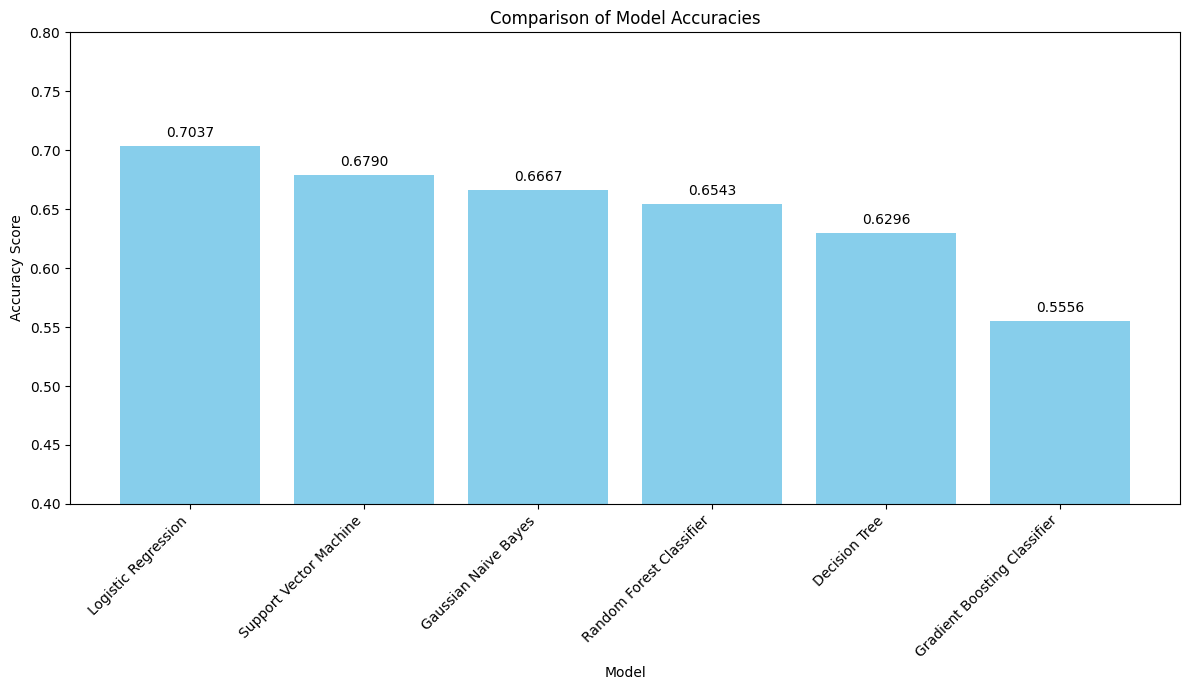


Model Accuracies (sorted):
 Logistic Regression             0.703704
Support Vector Machine          0.679012
Gaussian Naive Bayes            0.666667
Random Forest Classifier        0.654321
Decision Tree                   0.629630
Gradient Boosting Classifier    0.555556
dtype: float64


In [10]:
import matplotlib.pyplot as plt
import pandas as pd

# Convert the dictionary to a pandas Series for easier plotting
accuracies_series = pd.Series(model_accuracies)

# Sort the accuracies for better visualization
accuracies_series = accuracies_series.sort_values(ascending=False)

# Create the bar plot
plt.figure(figsize=(12, 7))
plt.bar(accuracies_series.index, accuracies_series.values, color='skyblue')
plt.xlabel('Model')
plt.ylabel('Accuracy Score')
plt.title('Comparison of Model Accuracies')
plt.xticks(rotation=45, ha='right') # Rotate labels for better readability
plt.ylim(0.4, 0.8) # Set a reasonable y-axis limit for better comparison

# Add accuracy values on top of the bars
for index, value in enumerate(accuracies_series.values):
    plt.text(index, value + 0.005, f'{value:.4f}', ha='center', va='bottom')

plt.tight_layout() # Adjust layout to prevent labels from overlapping
plt.show()

print('\nModel Accuracies (sorted):\n', accuracies_series)


## Summary of Model Performance

### Subtask:
Summarize the performance of all models and identify the best-performing one based on the accuracy scores.

**Analysis and Conclusion**:

Based on the accuracy scores calculated and visualized:

*   **Logistic Regression** achieved the highest accuracy of **0.7037**.
*   **Support Vector Machine** followed with an accuracy of **0.6790**.
*   **Gaussian Naive Bayes** had an accuracy of **0.6667**.
*   **Random Forest Classifier** had an accuracy of **0.6543**.
*   **Decision Tree Classifier** showed an accuracy of **0.6296**.
*   **Gradient Boosting Classifier** performed the lowest with an accuracy of **0.5556**.

**Best Performing Model**: Logistic Regression

**Overall**: The Logistic Regression model demonstrates the best performance among the evaluated models for this dataset, providing the highest accuracy in predicting heart disease.

## Final Task

### Subtask:
Summarize the performance of all models and identify the best-performing model based on the evaluation metrics, especially accuracy.


## Summary:

### Q&A
*   **Which model is the best-performing one based on evaluation metrics, especially accuracy?**
    Logistic Regression is the best-performing model, achieving the highest accuracy score of 0.7037.

### Data Analysis Key Findings
*   Six different machine learning models were trained and evaluated on the `HeartDiseases.csv` dataset, with their accuracy scores on the test set being:
    *   **Logistic Regression:** 0.7037
    *   **Support Vector Machine:** 0.6790
    *   **Gaussian Naive Bayes:** 0.6667
    *   **Random Forest Classifier:** 0.6543
    *   **Decision Tree Classifier:** 0.6296
    *   **Gradient Boosting Classifier:** 0.5556
*   Logistic Regression achieved the highest accuracy, making it the best-performing model among those evaluated.
*   The Gradient Boosting Classifier recorded the lowest accuracy of 0.5556.

### Insights or Next Steps
*   The superior performance of Logistic Regression suggests that a linear decision boundary might be sufficient for classifying heart disease in this dataset, indicating good interpretability.
*   Further hyperparameter tuning for the Logistic Regression model, and potentially other high-performing models like SVM and Gaussian Naive Bayes, could lead to even better predictive accuracy.
